In [ ]:

!pip install -q pandas numpy scikit-learn imbalanced-learn xgboost lightgbm shap matplotlib seaborn joblib
!pip install -q transformers datasets torch torchvision torchaudio
!pip install -q transformers datasets accelerate evaluate "torch>=2.0" sentencepiece
!pip install -q scikit-learn pandas


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Data Preprocessing**


In [ ]:

import os
import numpy as np
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42
DATA_PATH = "/content/SHILD2012_cens_eng_16-64.csv"

# Load dataset
df = pd.read_csv(DATA_PATH)
print("Loaded shape:", df.shape)
print("Columns sample:", list(df.columns)[:40])


Loaded shape: (18957, 244)
Columns sample: ['Unnamed: 0', 'respnb', 'gender', 'age', 'int_result', 'method', 'A1', 'A2', 'B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B9', 'B10', 'B11', 'B12', 'B13', 'B14', 'B15', 'B16', 'B17_a', 'B18', 'C1', 'C2', 'C3', 'C3a', 'C3b', 'C4', 'C5', 'C6', 'C7', 'C7a', 'C8', 'C9', 'C10', 'D1']


 **Binary target, drop rows with missing target and **drop** cols >20% missing**

In [ ]:
TARGET_NAME = "A1"


def map_target(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower()
    # textual mapping
    if s in {"satisfied", "very satisfied", "content", "contented", "1", "yes", "y", "true", "t"}:
        return 1
    if s in {"dissatisfied", "very dissatisfied", "discontent", "0", "no", "n", "false", "f"}:
        return 0
    # numeric scales (common 1-5)
    try:
        v = float(s)
        # Heuristic: >=4 -> satisfied, <=2 -> dissatisfied, 3 -> neutral => set to NaN
        if v >= 4:
            return 1
        if v <= 2:
            return 0
        return np.nan
    except:
        return np.nan

df[TARGET_NAME] = df[TARGET_NAME].apply(map_target)
print("Target value counts (including NaN):\n", df[TARGET_NAME].value_counts(dropna=False))

# Drop rows with no label
before = df.shape[0]
df = df[df[TARGET_NAME].notna()].reset_index(drop=True)
print(f"Dropped {before - df.shape[0]} rows without A1 label. New shape: {df.shape}")

# Drop columns with >20% missing values
missing_pct = df.isnull().mean().sort_values(ascending=False)
cols_to_drop = missing_pct[missing_pct > 0.20].index.tolist()
print(f"Dropping {len(cols_to_drop)} columns with >20% missing (examples):", cols_to_drop[:10])
df = df.drop(columns=cols_to_drop)
print("After dropping high-missing cols shape:", df.shape)

Target value counts (including NaN):
 A1
1.0    9752
NaN    8366
0.0     839
Name: count, dtype: int64
Dropped 8366 rows without A1 label. New shape: (10591, 244)
Dropping 132 columns with >20% missing (examples): ['G5_6', 'G5_4', 'G5_5', 'N6', 'N7', 'B16', 'F5', 'J5', 'F4', 'R8']
After dropping high-missing cols shape: (10591, 112)


**Separate numeric & categorical, iterative imputation for numeric**

In [ ]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if TARGET_NAME in num_cols:
    num_cols.remove(TARGET_NAME)
cat_cols = [c for c in df.columns if c not in num_cols and c != TARGET_NAME]

print("Numeric cols:", len(num_cols), "Categorical cols:", len(cat_cols))

# Iterative imputation on numeric columns (BayesianRidge default)
if num_cols:
    iter_imp = IterativeImputer(random_state=RANDOM_STATE)
    df[num_cols] = iter_imp.fit_transform(df[num_cols])
    print("Imputed numeric columns with IterativeImputer.")

# Encode categorical using OrdinalEncoder (suitable for many survey ordinal vars)
if cat_cols:
    oe = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    df[cat_cols] = oe.fit_transform(df[cat_cols].astype(str))
    print("Encoded categorical columns with OrdinalEncoder.")

# Outlier handling: replace values outside ±2σ with median (skip target)
for c in df.select_dtypes(include=[np.number]).columns:
    if c == TARGET_NAME:
        continue
    col = df[c]
    mean = col.mean()
    std = col.std()
    upper = mean + 2*std
    lower = mean - 2*std
    med = col.median()
    df.loc[(col > upper) | (col < lower), c] = med
print("Outlier handling done (±2σ -> median).")

# Remove zero-variance features
num_features = [c for c in df.select_dtypes(include=[np.number]).columns if c != TARGET_NAME]
vt = VarianceThreshold(threshold=0.0)
if num_features:
    vt.fit(df[num_features])
    support = vt.get_support()
    kept_numeric = [num_features[i] for i, v in enumerate(support) if v]
else:
    kept_numeric = []
final_features = list(dict.fromkeys(kept_numeric + cat_cols))
print("Kept feature count after variance threshold:", len(final_features))

# Keep final dataset with features + target
df = df[final_features + [TARGET_NAME]]
print("Preprocessed dataframe shape:", df.shape)

# Save preprocessed to disk for reproducibility
df.to_csv("preprocessed_shild_A1.csv", index=False)
print("Saved preprocessed_shild_A1.csv")

Numeric cols: 10 Categorical cols: 101
Imputed numeric columns with IterativeImputer.
Encoded categorical columns with OrdinalEncoder.
Outlier handling done (±2σ -> median).
Kept feature count after variance threshold: 111
Preprocessed dataframe shape: (10591, 112)
Saved preprocessed_shild_A1.csv


**Exploratory Data Analysis (EDA)**

EDA dataframe shape: (10591, 112)

Target distribution (A1):
A1
1.0    9752
0.0     839
Name: count, dtype: int64


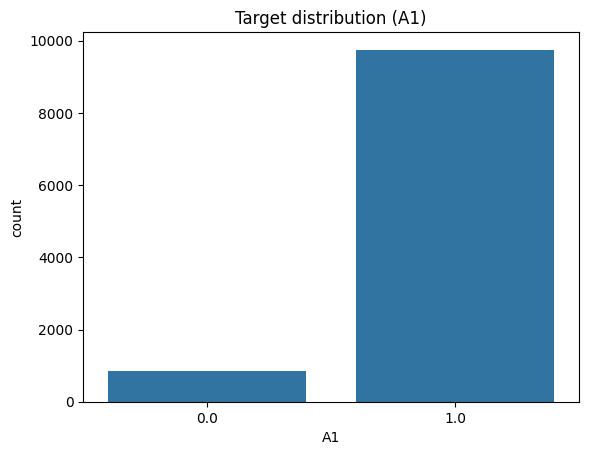

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,10591.0,9430.441790,5483.854373,1.0,4689.5,9373.0,14193.0,18956.0
respnb,10591.0,10233.298650,5653.087774,2.0,5602.0,10292.0,15112.0,19875.0
gender,10591.0,0.531867,0.499007,0.0,0.0,1.0,1.0,1.0
age,10591.0,42.973279,13.791574,16.0,33.0,45.0,55.0,64.0
A2,10591.0,2.699934,1.735656,0.0,0.0,4.0,4.0,4.0
...,...,...,...,...,...,...,...,...
N16,10591.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
Q1_b,10591.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
Q1_e,10591.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
Q1_g,10591.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0



Top missing (should be zero or small):
Series([], dtype: float64)


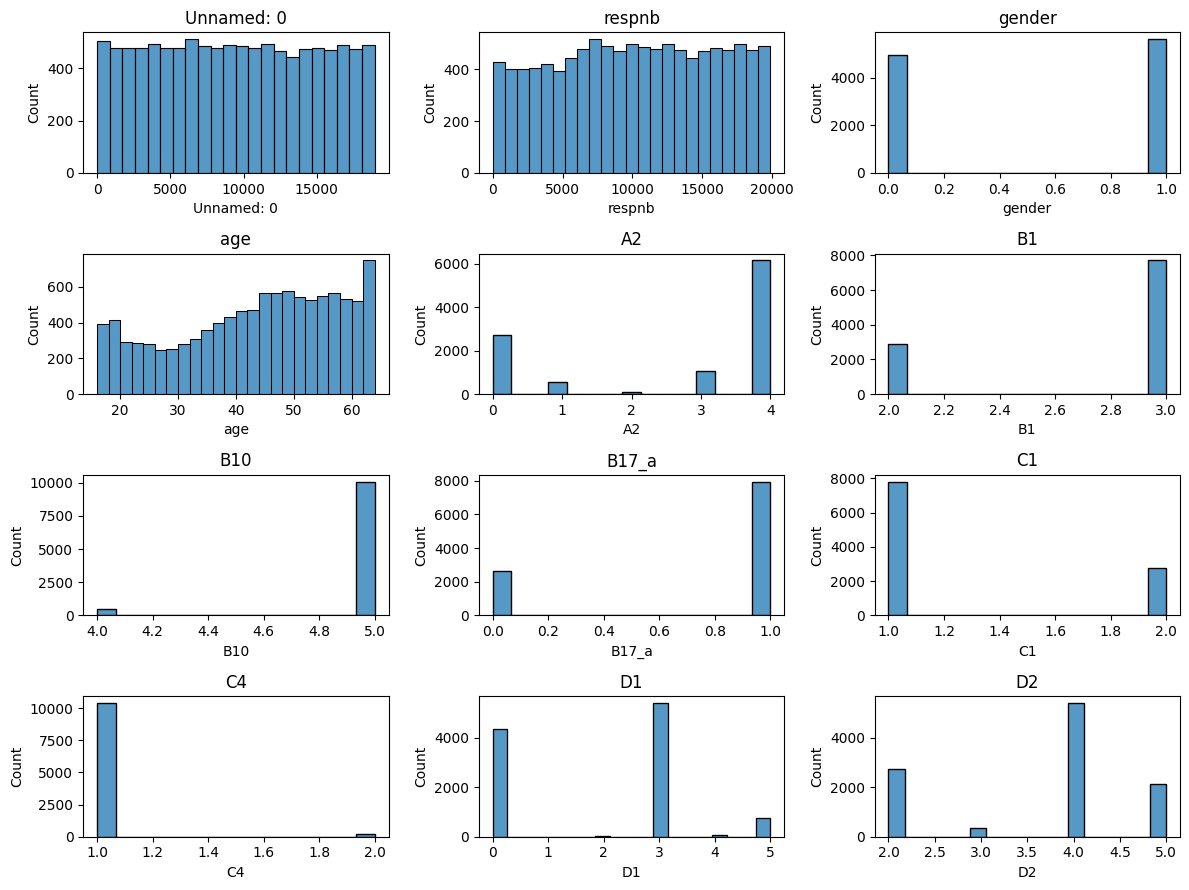

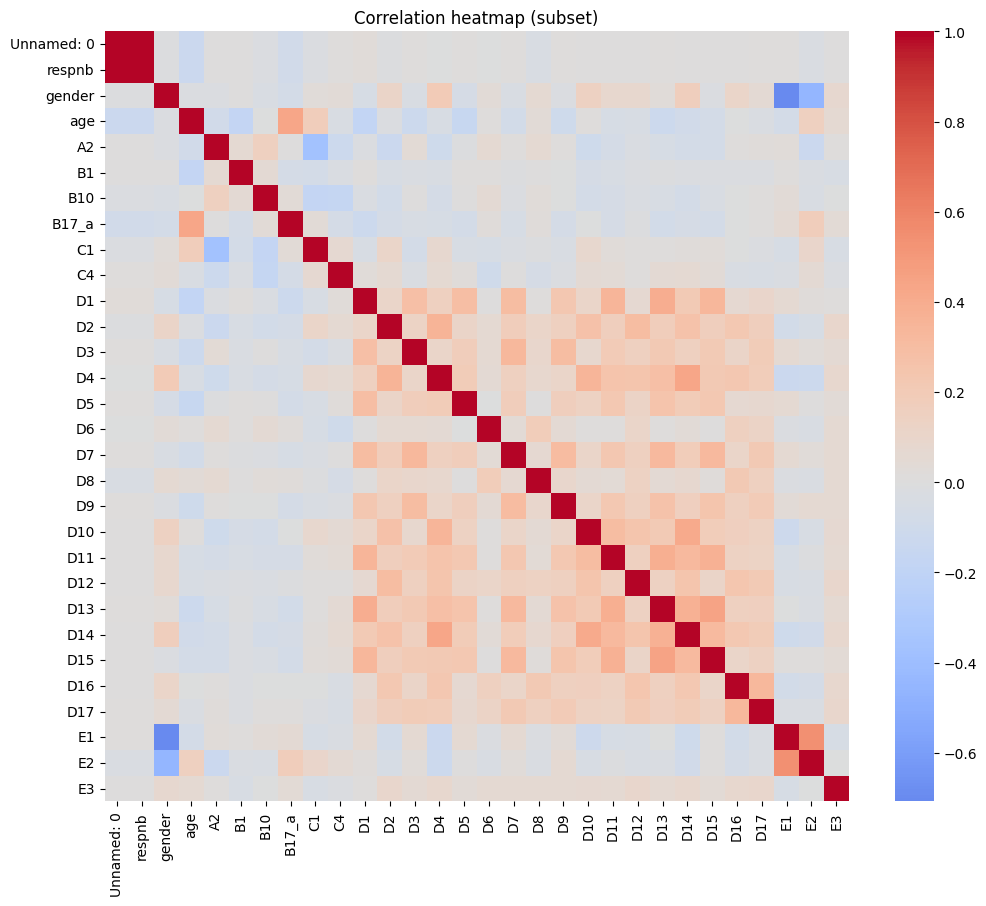

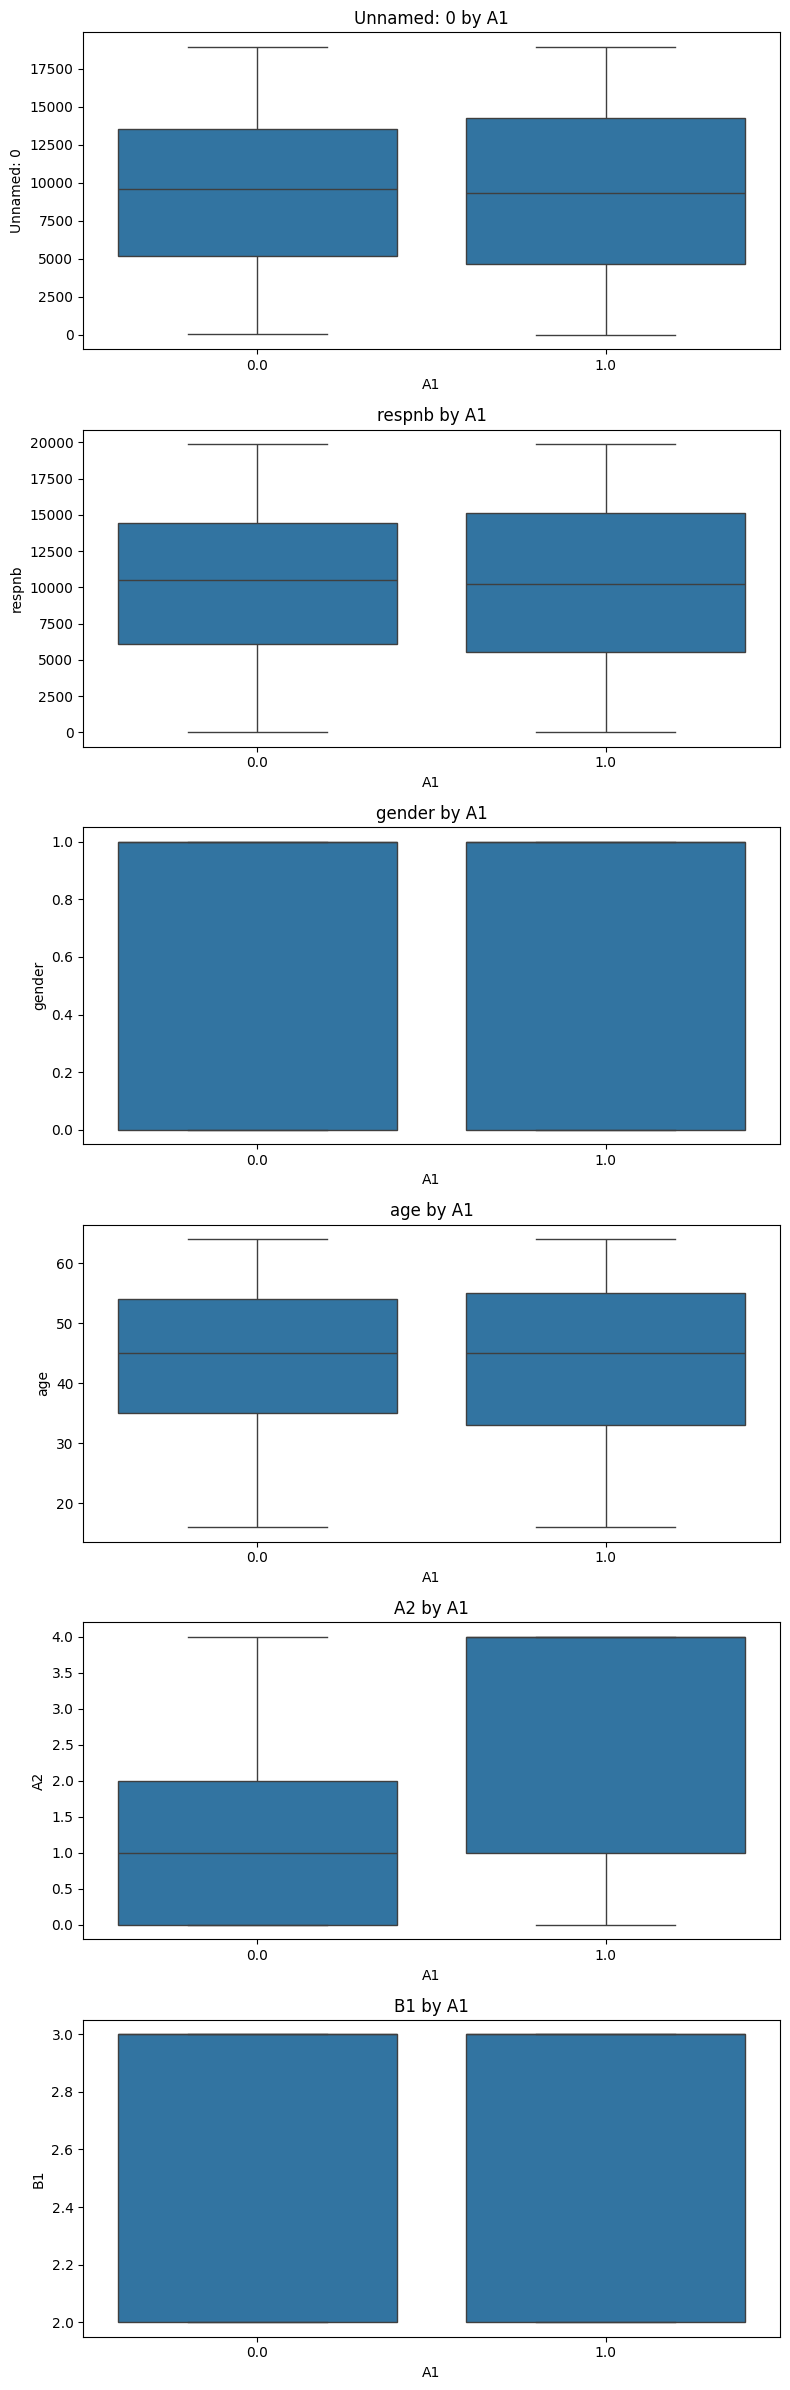

In [ ]:

# Load preprocessed
df = pd.read_csv("preprocessed_shild_A1.csv")
print("EDA dataframe shape:", df.shape)

# 1) Target distribution
print("\nTarget distribution (A1):")
print(df[TARGET_NAME].value_counts())
sns.countplot(x=TARGET_NAME, data=df)
plt.title("Target distribution (A1)")
plt.show()

# 2) Quick numeric summary
display(df.describe().T)

# 3) Missingness check (should be minimal after preprocessing)
missing_pct = df.isnull().mean().sort_values(ascending=False)
print("\nTop missing (should be zero or small):")
print(missing_pct[missing_pct>0].head())

# 4) Feature distribution plots (first up to 12 numeric features)
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if TARGET_NAME in num_cols:
    num_cols.remove(TARGET_NAME)
to_plot = num_cols[:12]
fig, axes = plt.subplots(nrows=min(4,len(to_plot)//3+1), ncols=3, figsize=(12,9))
axes = axes.flatten()
for ax, c in zip(axes, to_plot):
    sns.histplot(df[c], ax=ax, kde=False)
    ax.set_title(c)
plt.tight_layout()
plt.show()

# 5) Correlation matrix (heatmap) for top 30 features to inspect multicollinearity
corr = df.corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr.iloc[:30, :30], cmap="coolwarm", center=0, annot=False)
plt.title("Correlation heatmap (subset)")
plt.show()

# 6) Feature vs target (boxplots for numeric features vs A1)
fig, axes = plt.subplots(nrows=min(6,len(to_plot)), ncols=1, figsize=(8, 4*min(6,len(to_plot))))
for i, c in enumerate(to_plot[:6]):
    sns.boxplot(x=TARGET_NAME, y=c, data=df, ax=axes[i])
    axes[i].set_title(f"{c} by {TARGET_NAME}")
plt.tight_layout()
plt.show()


**Train/test split then dual resampling (SMOTE -> undersample)**

In [ ]:
X = df.drop(columns=[TARGET_NAME])
y = df[TARGET_NAME].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20,stratify=y, random_state=RANDOM_STATE, shuffle=True)
print("Train/test shapes:", X_train.shape, X_test.shape)
print("Train class dist:", Counter(y_train))

# SMOTE to bring minority to 40% of majority, then undersample majority
sm = SMOTE(sampling_strategy=0.4, random_state=RANDOM_STATE) # Removed n_jobs
X_sm, y_sm = sm.fit_resample(X_train, y_train)
print("After SMOTE class dist:", Counter(y_sm))

rus = RandomUnderSampler(random_state=RANDOM_STATE)
X_bal, y_bal = rus.fit_resample(X_sm, y_sm)
print("After undersample class dist:", Counter(y_bal))

Train/test shapes: (8472, 111) (2119, 111)
Train class dist: Counter({1: 7801, 0: 671})
After SMOTE class dist: Counter({1: 7801, 0: 3120})
After undersample class dist: Counter({0: 3120, 1: 3120})


**RFECV (recursive feature elimination with CV) using RandomForest**

In [ ]:
# RFECV (recursive feature elimination with CV) using RandomForest
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFECV

rf_est = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rfecv = RFECV(estimator=rf_est, step=1, cv=5, scoring='accuracy', n_jobs=-1)
print("Running RFECV (this may take a few minutes depending on feature count)...")
rfecv.fit(X_bal, y_bal)
print("RFECV done.")
print("Optimal number of features:", rfecv.n_features_)

# Get selected feature names
selected_mask = rfecv.support_
selected_features = X.columns[selected_mask].tolist()
print("Selected features (len={}):\n".format(len(selected_features)), selected_features)

# Reduce training and test sets to selected features for downstream modeling
X_train_sel = X_train[selected_features]
X_test_sel  = X_test[selected_features]
X_bal_sel   = pd.DataFrame(X_bal, columns=X.columns)[selected_features]

# Save selected feature list
pd.Series(selected_features).to_csv("selected_features_A1.csv", index=False)
print("Saved selected_features_A1.csv")

Running RFECV (this may take a few minutes depending on feature count)...
RFECV done.
Optimal number of features: 23
Selected features (len=23):
 ['Unnamed: 0', 'respnb', 'age', 'A2', 'C1', 'D2', 'D4', 'D6', 'D8', 'D10', 'D14', 'D15', 'E2', 'E17', 'F15', 'G1', 'G7', 'H1', 'J14', 'M2', 'M6', 'M8', 'pervgt']
Saved selected_features_A1.csv


**Quick view of feature ranking and plot RFECV scores**

,feature,ranking,selected
4,A2,1,1
8,C1,1,1
19,D10,1,1
23,D14,1,1
24,D15,1,1
11,D2,1,1
13,D4,1,1
15,D6,1,1
17,D8,1,1
34,E17,1,1


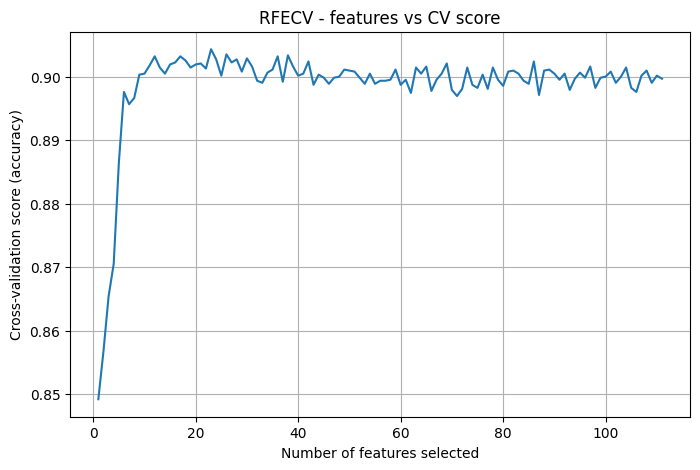

In [ ]:

# rfecv.ranking_ gives ranking, lower is better (1 = selected)
ranking_df = pd.DataFrame({
    "feature": X.columns,
    "ranking": rfecv.ranking_,
    "selected": rfecv.support_.astype(int)
}).sort_values(["selected", "ranking", "feature"], ascending=[False, True, True])

display(ranking_df.head(40))

# Plot number of features vs cross-validation score
plt.figure(figsize=(8,5))
plt.plot(range(1, len(rfecv.cv_results_['mean_test_score']) + 1), rfecv.cv_results_['mean_test_score'])
plt.xlabel("Number of features selected")
plt.ylabel("Cross-validation score (accuracy)")
plt.title("RFECV - features vs CV score")
plt.grid(True)
plt.show()

**Imports, config, and device**

In [ ]:
import os, random, math
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed,
                          EarlyStoppingCallback)

# Config
RANDOM_STATE = 42
PREPROCESSED_CSV = "preprocessed_shild_A1.csv"
SELECTED_FEATURES_CSV = "selected_features_A1.csv"
TARGET_NAME = "A1"
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 256
BATCH_SIZE = 16
NUM_EPOCHS = 5
LR = 2e-5

set_seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


**Load preprocessed data and selected features (with safety checks)**

In [ ]:
# Load preprocessed CSV
if not os.path.exists(PREPROCESSED_CSV):
    raise FileNotFoundError(f"{PREPROCESSED_CSV} .")

df = pd.read_csv(PREPROCESSED_CSV)
print("Loaded preprocessed dataframe:", df.shape)
if TARGET_NAME not in df.columns:
    raise SystemExit(f"Target column '{TARGET_NAME}' not found in {PREPROCESSED_CSV}. Check your preprocessed file.")

# Load selected features if available
if os.path.exists(SELECTED_FEATURES_CSV):
    sel = pd.read_csv(SELECTED_FEATURES_CSV, header=None).iloc[:,0].astype(str).tolist()
    selected_features = [c for c in sel if c in df.columns]
    print(f"Loaded {len(selected_features)} selected features from {SELECTED_FEATURES_CSV}")
else:
    # fallback: choose up to 27 columns by variance (excluding target)
    cand = [c for c in df.columns if c != TARGET_NAME]
    variances = df[cand].var().sort_values(ascending=False)
    topk = min(27, len(variances))
    selected_features = variances.index[:topk].tolist()
    print(f"No selected_features file found. Auto-picked top {topk} features by variance.")

print("Selected feature list (first 30):", selected_features[:30])


Loaded preprocessed dataframe: (10591, 112)
Loaded 23 selected features from selected_features_A1.csv
Selected feature list (first 30): ['Unnamed: 0', 'respnb', 'age', 'A2', 'C1', 'D2', 'D4', 'D6', 'D8', 'D10', 'D14', 'D15', 'E2', 'E17', 'F15', 'G1', 'G7', 'H1', 'J14', 'M2', 'M6', 'M8', 'pervgt']


Print unique values per selected feature

In [ ]:
for c in selected_features:
    unique_vals = df[c].dropna().unique()
    # sample if many unique values
    if len(unique_vals) > 20:
        uniques_sample = np.sort(df[c].dropna().unique())[:20].tolist()
        print(f"{c} (n_unique={len(unique_vals)}): sample -> {uniques_sample} ...")
    else:
        print(f"{c} (n_unique={len(unique_vals)}): {np.sort(unique_vals).tolist()}")


Unnamed: 0 (n_unique=10591): sample -> [1.0, 5.0, 6.0, 7.0, 8.0, 9.0, 12.0, 13.0, 15.0, 19.0, 20.0, 21.0, 23.0, 24.0, 25.0, 26.0, 27.0, 28.0, 29.0, 31.0] ...
respnb (n_unique=10591): sample -> [2.0, 8.0, 9.0, 11.0, 12.0, 13.0, 17.0, 19.0, 21.0, 26.0, 27.0, 28.0, 30.0, 31.0, 33.0, 34.0, 35.0, 36.0, 37.0, 39.0] ...
age (n_unique=49): sample -> [16.0, 17.0, 18.0, 19.0, 20.0, 21.0, 22.0, 23.0, 24.0, 25.0, 26.0, 27.0, 28.0, 29.0, 30.0, 31.0, 32.0, 33.0, 34.0, 35.0] ...
A2 (n_unique=5): [0.0, 1.0, 2.0, 3.0, 4.0]
C1 (n_unique=2): [1.0, 2.0]
D2 (n_unique=4): [2.0, 3.0, 4.0, 5.0]
D4 (n_unique=6): [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
D6 (n_unique=3): [3.0, 4.0, 5.0]
D8 (n_unique=4): [2.0, 3.0, 4.0, 5.0]
D10 (n_unique=7): [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0]
D14 (n_unique=6): [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
D15 (n_unique=7): [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0]
E2 (n_unique=113): sample -> [0.0, 40.0, 41.0, 42.0, 43.0, 44.0, 45.0, 46.0, 47.0, 48.0, 49.0, 50.0, 51.0, 52.0, 53.0, 54.0, 55.0, 56.0, 57.0, 58.

**Provide mapping dictionaries for nicer sentences**

In [ ]:
# Example mapping skeleton. Fill these dictionaries using the unique values printed.
# Example:
# mappings = {
#    "A2": {0: "poor health", 1: "average health", 2: "good health", 3: "very good health"},
#    "A4": {0: "no income", 1: "low income", 2: "medium income", 3: "high income"},

mappings = {}

# If you fill mappings, ensure keys match 'selected_features' names exactly.
print("Mappings ready for {} features.".format(len(mappings)))


Mappings ready for 0 features.


**Create human-readable sentence column**

In [ ]:
def make_phrase(col, val):
    # use mapping if present
    if col in mappings and val in mappings[col]:
        return mappings[col][val]
    # fallback: generate reasonable phrase
    # if column name is short like 'A2' try prettier label
    pretty_col = col.replace("_", " ").lower()
    if pd.isna(val):
        return None
    # textual values
    if isinstance(val, str):
        v = val.strip()
        return f"{pretty_col} = {v}"
    # integer-like levels
    try:
        fv = float(val)
        if fv.is_integer() and -2 <= int(fv) <= 20:
            return f"{pretty_col} level {int(fv)}"
        return f"{pretty_col}: {round(fv, 3)}"
    except:
        return f"{pretty_col} = {val}"

# Build sentences using only selected_features (keeps concise)
sentences = []
for _, row in df[selected_features].iterrows():
    parts = []
    for c in selected_features:
        p = make_phrase(c, row[c])
        if p:
            parts.append(p)
    # join and produce one sentence per row
    s = "; ".join(parts)
    sentences.append(s)

df['sentence'] = sentences
print("Generated sentences for {} rows. Sample:".format(len(df)))
print(df['sentence'].head(5).tolist())


Generated sentences for 10591 rows. Sample:
['unnamed: 0 level 1; respnb level 2; age: 39.0; a2 level 4; c1 level 1; d2 level 4; d4 level 3; d6 level 5; d8 level 4; d10 level 3; d14 level 3; d15 level 3; e2: 75.0; e17 level 7; f15 level 9; g1 level 1; g7 level 1; h1 level 10; j14 level 5; m2 level 9; m6: 1000.0; m8 level 3; pervgt: 145.904', 'unnamed: 0 level 5; respnb level 8; age: 36.0; a2 level 4; c1 level 2; d2 level 4; d4 level 3; d6 level 5; d8 level 2; d10 level 3; d14 level 3; d15 level 3; e2: 77.0; e17 level 7; f15 level 10; g1 level 1; g7 level 1; h1 level 10; j14 level 4; m2 level 9; m6: 500.0; m8 level 3; pervgt: 192.089', 'unnamed: 0 level 6; respnb level 9; age: 39.0; a2 level 0; c1 level 1; d2 level 5; d4 level 5; d6 level 3; d8 level 4; d10 level 6; d14 level 5; d15 level 3; e2: 88.0; e17 level 7; f15 level 10; g1 level 1; g7 level 2; h1 level 8; j14 level 6; m2 level 6; m6: 500.0; m8 level 1; pervgt: 175.361', 'unnamed: 0 level 7; respnb level 11; age: 53.0; a2 level 4

**Prepare HF Dataset (train/test split, conversion)**

In [ ]:
#  only sentence + target, drop NA
df2 = df[['sentence', TARGET_NAME]].dropna().copy()
df2[TARGET_NAME] = df2[TARGET_NAME].astype(int)
print("Data for LLM:", df2.shape)
print(df2[TARGET_NAME].value_counts())

train_df, test_df = train_test_split(df2, test_size=0.20, stratify=df2[TARGET_NAME], random_state=RANDOM_STATE)
print("Train/test shapes:", train_df.shape, test_df.shape)

hf_train = Dataset.from_pandas(train_df.rename(columns={TARGET_NAME:'label'}), preserve_index=False)
hf_test  = Dataset.from_pandas(test_df.rename(columns={TARGET_NAME:'label'}), preserve_index=False)
dataset = DatasetDict({"train": hf_train, "test": hf_test})


Data for LLM: (10591, 2)
A1
1    9752
0     839
Name: count, dtype: int64
Train/test shapes: (8472, 2) (2119, 2)


**Tokenizer / model and tokenization**

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

def tokenize_fn(batch):
    return tokenizer(batch["sentence"], truncation=True, padding=False, max_length=MAX_LENGTH)

tokenized = dataset.map(tokenize_fn, batched=True, remove_columns=["sentence"])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print("Tokenization complete. Example tokenized entry keys:", tokenized["train"].column_names)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/8472 [00:00<?, ? examples/s]

Map:   0%|          | 0/2119 [00:00<?, ? examples/s]

Tokenization complete. Example tokenized entry keys: ['label', 'input_ids', 'token_type_ids', 'attention_mask']


**Metrics function, training args, Trainer**

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from transformers import TrainingArguments, Trainer, EarlyStoppingCallback

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": float(accuracy_score(labels, preds)),
        "precision": float(precision_score(labels, preds, average='macro', zero_division=0)),
        "recall": float(recall_score(labels, preds, average='macro', zero_division=0)),
        "f1": float(f1_score(labels, preds, average='macro', zero_division=0)),
    }

training_args = TrainingArguments(
    output_dir="llm_life_satisfaction",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=LR,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    num_train_epochs=NUM_EPOCHS,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_steps=50,
    save_total_limit=2,
    seed=RANDOM_STATE,
    fp16=torch.cuda.is_available(),
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized['train'],
    eval_dataset=tokenized['test'],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)

**Train and save model**

In [ ]:
# Train
train_result = trainer.train()
trainer.save_model("life_satisfaction_BERT_model")
tokenizer.save_pretrained("life_satisfaction_BERT_model")
print("Training finished. Saved model to ./life_satisfaction_BERT_model")
print("Training metrics:", train_result.metrics)


wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Find your API key here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: fahim-khan08 (fahim-khan08-north-south-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.232500,0.273157,0.920717,0.460359,0.500000,0.479361
2,0.247000,0.215019,0.927324,0.753192,0.693982,0.718572
3,0.169900,0.206013,0.932987,0.788997,0.678018,0.717190
4,0.222000,0.191933,0.932987,0.788997,0.678018,0.717190
5,0.147800,0.190597,0.933459,0.792192,0.678274,0.718201


Training finished. Saved model to ./life_satisfaction_BERT_model
Training metrics: {'train_runtime': 640.5642, 'train_samples_per_second': 66.129, 'train_steps_per_second': 4.137, 'total_flos': 2862422171253600.0, 'train_loss': 0.21566035756525004, 'epoch': 5.0}


**valuate, classification report, and sample inference**

In [ ]:
# Evaluate
eval_res = trainer.evaluate()
print("Evaluation:", eval_res)

# Predictions & sklearn report
preds_out = trainer.predict(tokenized['test'])
logits = preds_out.predictions
preds = np.argmax(logits, axis=1)
labels = preds_out.label_ids

from sklearn.metrics import classification_report, confusion_matrix
print("\nClassification report:\n")
print(classification_report(labels, preds, digits=4))
print("Confusion matrix:\n", confusion_matrix(labels, preds))

# Quick inference examples
from transformers import pipeline
pipe = pipeline("text-classification", model="life_satisfaction_BERT_model", tokenizer="life_satisfaction_BERT_model",
                device=0 if torch.cuda.is_available() else -1)

examples = df['sentence'].sample(3, random_state=RANDOM_STATE).tolist()
print("Sample predictions:")
for ex in examples:
    print(ex[:200], "->", pipe(ex))


Evaluation: {'eval_loss': 0.2150191366672516, 'eval_accuracy': 0.9273242095327985, 'eval_precision': 0.7531917265986509, 'eval_recall': 0.6939817187766957, 'eval_f1': 0.71857191152323, 'eval_runtime': 4.4929, 'eval_samples_per_second': 471.632, 'eval_steps_per_second': 29.602, 'epoch': 5.0}

Classification report:

              precision    recall  f1-score   support

           0     0.5556    0.4167    0.4762       168
           1     0.9508    0.9713    0.9610      1951

    accuracy                         0.9273      2119
   macro avg     0.7532    0.6940    0.7186      2119
weighted avg     0.9195    0.9273    0.9225      2119

Confusion matrix:
 [[  70   98]
 [  56 1895]]


Device set to use cuda:0


Sample predictions:
unnamed: 0: 18510.0; respnb: 19429.0; age: 53.0; a2 level 4; c1 level 1; d2 level 4; d4 level 0; d6 level 4; d8 level 4; d10 level 3; d14 level 3; d15 level 3; e2: 120.0; e17 level 7; f15 level 10; g1 -> [{'label': 'LABEL_1', 'score': 0.9647355079650879}]
unnamed: 0: 15940.0; respnb: 16859.0; age: 58.0; a2 level 4; c1 level 2; d2 level 5; d4 level 3; d6 level 5; d8 level 5; d10 level 3; d14 level 5; d15 level 6; e2: 65.0; e17 level 7; f15 level 9; g1 l -> [{'label': 'LABEL_1', 'score': 0.9622469544410706}]
unnamed: 0: 8633.0; respnb: 9552.0; age: 47.0; a2 level 0; c1 level 1; d2 level 2; d4 level 3; d6 level 4; d8 level 4; d10 level 3; d14 level 3; d15 level 3; e2: 80.0; e17 level 7; f15 level 10; g1 le -> [{'label': 'LABEL_1', 'score': 0.864229679107666}]


**Save splits and optional artifacts**

In [ ]:
train_df.to_csv("llm_train_split.csv", index=False)
test_df.to_csv("llm_test_split.csv", index=False)
pd.Series(selected_features).to_csv("used_selected_features_for_llm.csv", index=False, header=False)
print("Saved splits and used features list.")


Saved splits and used features list.


**Logistic Regression**

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

print("Training Logistic Regression...")

lr = LogisticRegression(max_iter=5000)
lr.fit(X_bal_sel, y_bal)

# Predictions
lr_preds = lr.predict(X_test_sel)
lr_probs = lr.predict_proba(X_test_sel)[:, 1]

# Metrics
lr_acc  = accuracy_score(y_test, lr_preds)
lr_prec = precision_score(y_test, lr_preds)
lr_rec  = recall_score(y_test, lr_preds)
lr_f1   = f1_score(y_test, lr_preds)
lr_roc  = roc_auc_score(y_test, lr_probs)

print("---- Logistic Regression ----")
print("Accuracy :", round(lr_acc, 4))
print("Precision:", round(lr_prec, 4))
print("Recall   :", round(lr_rec, 4))
print("F1-score :", round(lr_f1, 4))
print("ROC-AUC  :", round(lr_roc, 4))


Training Logistic Regression...
---- Logistic Regression ----
Accuracy : 0.7381
Precision: 0.9691
Recall   : 0.7391
F1-score : 0.8386
ROC-AUC  : 0.8044


**Random Forest**

In [ ]:

from sklearn.ensemble import RandomForestClassifier

print("Training Random Forest...")

rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_bal_sel, y_bal)

rf_preds = rf.predict(X_test_sel)
rf_probs = rf.predict_proba(X_test_sel)[:, 1]

rf_acc  = accuracy_score(y_test, rf_preds)
rf_prec = precision_score(y_test, rf_preds)
rf_rec  = recall_score(y_test, rf_preds)
rf_f1   = f1_score(y_test, rf_preds)
rf_roc  = roc_auc_score(y_test, rf_probs)

print("---- Random Forest ----")
print("Accuracy :", round(rf_acc, 4))
print("Precision:", round(rf_prec, 4))
print("Recall   :", round(rf_rec, 4))
print("F1-score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_roc, 4))


Training Random Forest...
---- Random Forest ----
Accuracy : 0.9179
Precision: 0.954
Recall   : 0.9569
F1-score : 0.9555
ROC-AUC  : 0.8768


**XGBoost**

In [ ]:

from xgboost import XGBClassifier

print("Training XGBoost...")

xgb = XGBClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)
xgb.fit(X_bal_sel, y_bal)

xgb_preds = xgb.predict(X_test_sel)
xgb_probs = xgb.predict_proba(X_test_sel)[:, 1]

xgb_acc  = accuracy_score(y_test, xgb_preds)
xgb_prec = precision_score(y_test, xgb_preds)
xgb_rec  = recall_score(y_test, xgb_preds)
xgb_f1   = f1_score(y_test, xgb_preds)
xgb_roc  = roc_auc_score(y_test, xgb_probs)

print("---- XGBoost ----")
print("Accuracy :", round(xgb_acc, 4))
print("Precision:", round(xgb_prec, 4))
print("Recall   :", round(xgb_rec, 4))
print("F1-score :", round(xgb_f1, 4))
print("ROC-AUC  :", round(xgb_roc, 4))


Training XGBoost...
---- XGBoost ----
Accuracy : 0.9198
Precision: 0.9555
Recall   : 0.9575
F1-score : 0.9565
ROC-AUC  : 0.8897


**LightGBM**

In [ ]:

from lightgbm import LGBMClassifier

print("Training LightGBM...")

def clean_col_names(df):
    cols = df.columns
    new_cols = []
    for col in cols:
        new_col = str(col).replace(":", "_").replace(" ", "_").replace("[", "").replace("]", "").replace("<", "").replace(">", "").replace("=", "").replace(".", "_") # Added .replace(".", "_")
        new_cols.append(new_col)
    df.columns = new_cols
    return df

X_bal_sel_cleaned = clean_col_names(X_bal_sel.copy())
X_test_sel_cleaned = clean_col_names(X_test_sel.copy())

lgb = LGBMClassifier(
    n_estimators=400,
    learning_rate=0.05,
    random_state=42
)
lgb.fit(X_bal_sel_cleaned, y_bal)

lgb_preds = lgb.predict(X_test_sel_cleaned)
lgb_probs = lgb.predict_proba(X_test_sel_cleaned)[:, 1]

lgb_acc  = accuracy_score(y_test, lgb_preds)
lgb_prec = precision_score(y_test, lgb_preds)
lgb_rec  = recall_score(y_test, lgb_preds)
lgb_f1   = f1_score(y_test, lgb_preds)
lgb_roc  = roc_auc_score(y_test, lgb_probs)

print("---- LightGBM ----")
print("Accuracy :", round(lgb_acc, 4))
print("Precision:", round(lgb_prec, 4))
print("Recall   :", round(lgb_rec, 4))
print("F1-score :", round(lgb_f1, 4))
print("ROC-AUC  :", round(lgb_roc, 4))

Training LightGBM...
[LightGBM] [Info] Number of positive: 3120, number of negative: 3120
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002762 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 5862
[LightGBM] [Info] Number of data points in the train set: 6240, number of used features: 23
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
---- LightGBM ----
Accuracy : 0.925
Precision: 0.96
Recall   : 0.9585
F1-score : 0.9592
ROC-AUC  : 0.8953


**SVM (RBF Kernel)**

In [ ]:

from sklearn.svm import SVC

print("Training SVM (RBF)...")

svm_rbf = SVC(kernel='rbf', C=1.0, probability=True)
svm_rbf.fit(X_bal_sel, y_bal)

svm_rbf_preds = svm_rbf.predict(X_test_sel)
svm_rbf_probs = svm_rbf.predict_proba(X_test_sel)[:, 1]

svm_rbf_acc  = accuracy_score(y_test, svm_rbf_preds)
svm_rbf_prec = precision_score(y_test, svm_rbf_preds)
svm_rbf_rec  = recall_score(y_test, svm_rbf_preds)
svm_rbf_f1   = f1_score(y_test, svm_rbf_preds)
svm_rbf_roc  = roc_auc_score(y_test, svm_rbf_probs)

print("---- SVM (RBF) ----")
print("Accuracy :", round(svm_rbf_acc, 4))
print("Precision:", round(svm_rbf_prec, 4))
print("Recall   :", round(svm_rbf_rec, 4))
print("F1-score :", round(svm_rbf_f1, 4))
print("ROC-AUC  :", round(svm_rbf_roc, 4))


Training SVM (RBF)...
---- SVM (RBF) ----
Accuracy : 0.7688
Precision: 0.9398
Recall   : 0.8001
F1-score : 0.8643
ROC-AUC  : 0.6277


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd


**KNN Classifier**

KNN RESULTS
Accuracy : 0.6455875412930627
Precision: 0.8617974592244223
Recall   : 0.6455875412930627
F1 Score : 0.7265007940342133

Classification Report:
              precision    recall  f1-score   support

           0       0.09      0.40      0.15       168
           1       0.93      0.67      0.78      1951

    accuracy                           0.65      2119
   macro avg       0.51      0.53      0.46      2119
weighted avg       0.86      0.65      0.73      2119



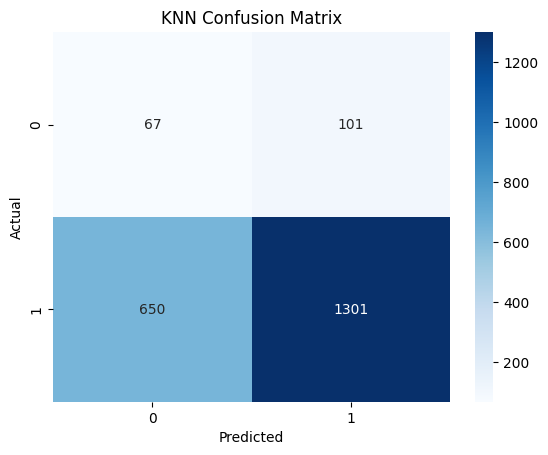

In [ ]:
# KNN Classifier (k=5 is default)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_bal_sel, y_bal)

# Predictions
y_pred_knn = knn.predict(X_test_sel)

# Evaluation
acc = accuracy_score(y_test, y_pred_knn)
prec = precision_score(y_test, y_pred_knn, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred_knn, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred_knn, average='weighted', zero_division=0)

print("KNN RESULTS")
print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1 Score :", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d")
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


**Naive Bayes**

 NAIVE BAYES RESULTS
Accuracy : 0.7654554034922133
Precision: 0.9019596948433506
Recall   : 0.7654554034922133
F1 Score : 0.8150019130489274

Classification Report:
              precision    recall  f1-score   support

           0       0.20      0.65      0.30       168
           1       0.96      0.78      0.86      1951

    accuracy                           0.77      2119
   macro avg       0.58      0.71      0.58      2119
weighted avg       0.90      0.77      0.82      2119



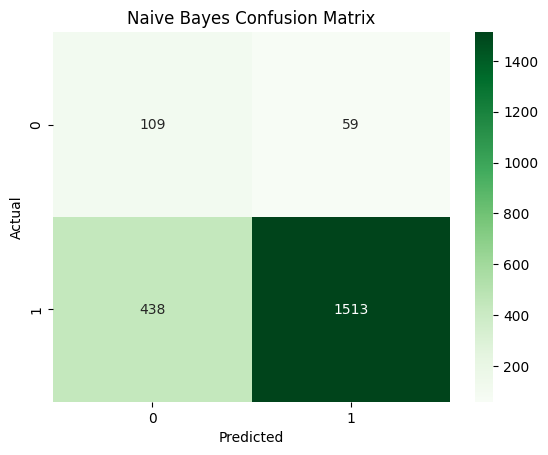

In [ ]:
# Naive Bayes (Gaussian NB)
nb = GaussianNB()
nb.fit(X_bal_sel, y_bal)

# Predictions
y_pred_nb = nb.predict(X_test_sel)

# Evaluation
acc = accuracy_score(y_test, y_pred_nb)
prec = precision_score(y_test, y_pred_nb, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred_nb, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred_nb, average='weighted', zero_division=0)

print(" NAIVE BAYES RESULTS")
print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1 Score :", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_nb)
sns.heatmap(cm, annot=True, cmap="Greens", fmt="d")
plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


**import and helpers**

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC


results = {}


def evaluate_model(name, model, X_test, y_test):
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)

    results[name] = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1,
        "Predictions": preds,
        "Model": model
    }
    print(f"\n{name} Results:")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")

In [ ]:

import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, f1_score


RANDOM_STATE = 42
TARGET_NAME = "A1"
PREPROCESSED_CSV = "preprocessed_shild_A1.csv"
SELECTED_FEATURES_CSV = "selected_features_A1.csv"

# Load preprocessed CSV
if not os.path.exists(PREPROCESSED_CSV):
    raise FileNotFoundError(f"{PREPROCESSED_CSV} .")
df = pd.read_csv(PREPROCESSED_CSV)

# Load selected features
if not os.path.exists(SELECTED_FEATURES_CSV):
    raise FileNotFoundError(f"{SELECTED_FEATURES_CSV} .")
sel = pd.read_csv(SELECTED_FEATURES_CSV, header=None).iloc[:,0].astype(str).tolist()
selected_features = [c for c in sel if c in df.columns]

# Prepare data for modeling
X = df.drop(columns=[TARGET_NAME])
y = df[TARGET_NAME].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20,stratify=y, random_state=RANDOM_STATE, shuffle=True)

# SMOTE to bring minority to 40% of majority
sm = SMOTE(sampling_strategy=0.4, random_state=RANDOM_STATE)
X_sm, y_sm = sm.fit_resample(X_train, y_train)

# Undersample majority
rus = RandomUnderSampler(random_state=RANDOM_STATE)
X_bal, y_bal = rus.fit_resample(X_sm, y_sm)

# Reduce training and test sets to selected features
X_train_sel = X_train[selected_features]
X_test_sel  = X_test[selected_features]
X_bal_sel   = pd.DataFrame(X_bal, columns=X.columns)[selected_features]


models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "SVM (Linear)": SVC(kernel='linear', random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB()
}

results = []

for name, model in models.items():
    model.fit(X_bal_sel, y_bal)
    preds = model.predict(X_test_sel)

    acc = accuracy_score(y_test, preds)
    f1  = f1_score(y_test, preds, average='weighted')

    results.append([name, acc, f1])

results

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


[['Logistic Regression', 0.7409155261915998, 0.7983315472517011],
 ['Decision Tree', 0.8574799433695139, 0.8754391099788598],
 ['Random Forest', 0.9155261915998112, 0.9156406964605212],
 ['Gradient Boosting', 0.9226050023596036, 0.9228141367713735],
 ['SVM (Linear)', 0.7409155261915998, 0.7983851955251778],
 ['KNN', 0.6455875412930627, 0.7265007940342133],
 ['Naive Bayes', 0.7654554034922133, 0.8150019130489274]]

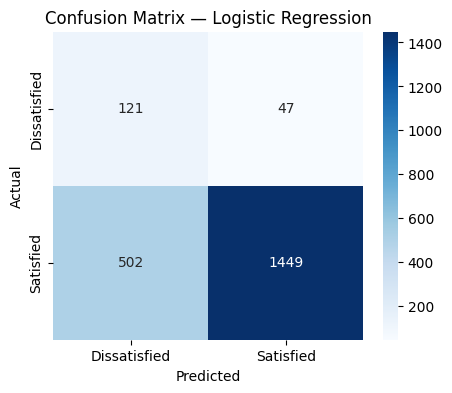

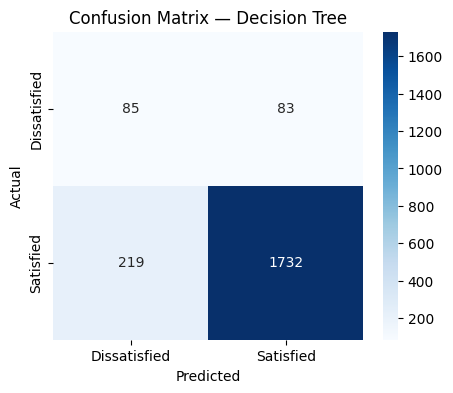

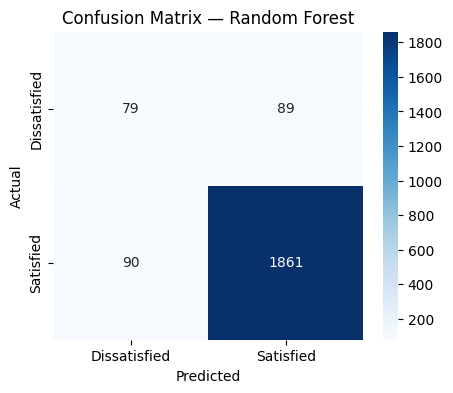

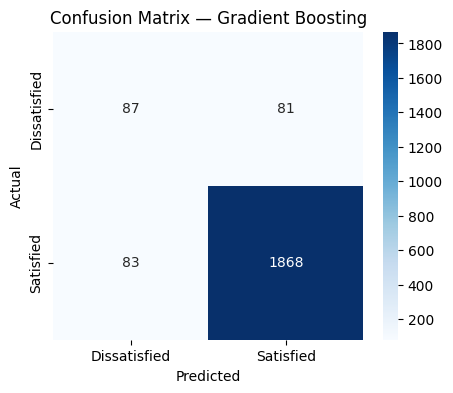

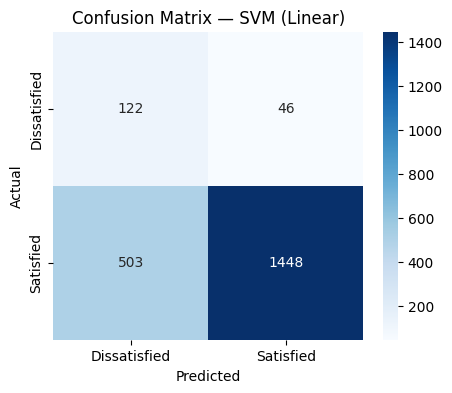

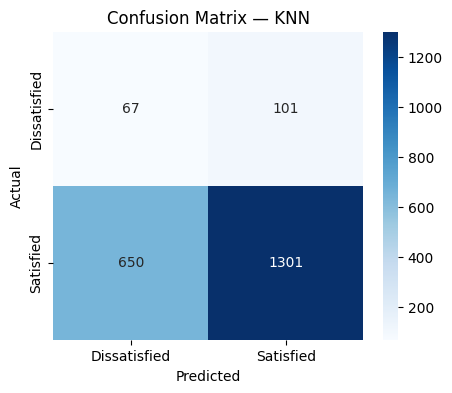

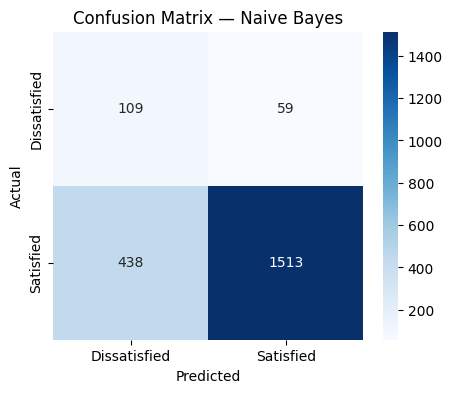

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Plot confusion matrix for each trained model
for name, model in models.items():
    preds = model.predict(X_test_sel)
    cm = confusion_matrix(y_test, preds)

    plt.figure(figsize=(5,4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Dissatisfied", "Satisfied"],
        yticklabels=["Dissatisfied", "Satisfied"]
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


**Result Table**

In [ ]:
import pandas as pd

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "F1"])
results_df.sort_values(by="F1", ascending=False, inplace=True)
results_df.reset_index(drop=True, inplace=True)

results_df


,Model,Accuracy,F1
0,Gradient Boosting,0.933459,0.920763
1,Logistic Regression,0.920717,0.896364
2,Decision Tree,0.894290,0.895949
3,SVM (Linear),0.915526,0.893614
4,Random Forest,0.922133,0.887857
5,KNN,0.915998,0.882054
6,Naive Bayes,0.866918,0.881773


from matplotlib import pyplot as plt
results_df['Accuracy'].plot(kind='hist', bins=20, title='Accuracy')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
results_df['F1'].plot(kind='hist', bins=20, title='F1')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
import seaborn as sns
results_df.groupby('Model').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
results_df.plot(kind='scatter', x='Accuracy', y='F1', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
results_df['Accuracy'].plot(kind='line', figsize=(8, 4), title='Accuracy')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
results_df['F1'].plot(kind='line', figsize=(8, 4), title='F1')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(results_df['Model'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(results_df, x='Accuracy', y='Model', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(results_df['Model'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(results_df, x='F1', y='Model', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

**Bar Plot Comparison**

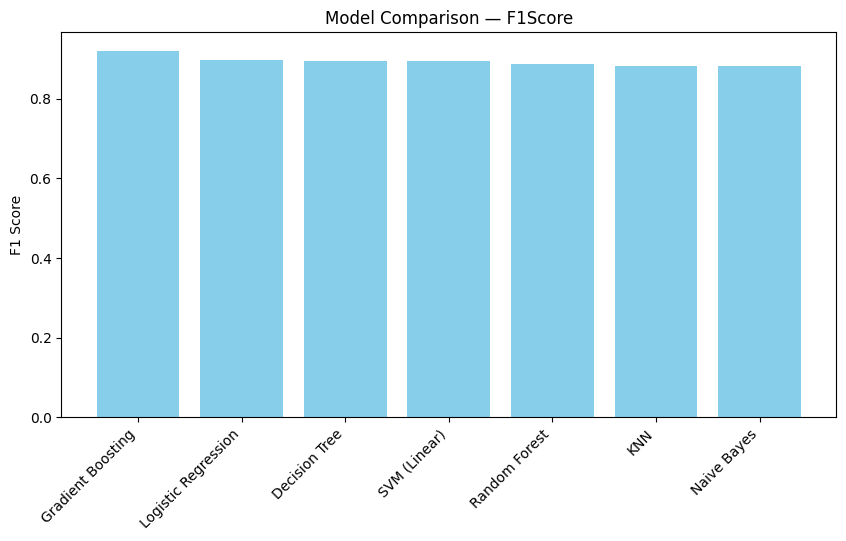

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.bar(results_df["Model"], results_df["F1"], color='skyblue')
plt.xticks(rotation=45, ha='right')
plt.ylabel("F1 Score")
plt.title("Model Comparison — F1Score")
plt.show()


**Identify Best Model**

In [ ]:
best_model_name = results_df.iloc[0]["Model"]
print("BEST MODEL:", best_model_name)

best_model = models[best_model_name]


BEST MODEL: Gradient Boosting


**Confusion Matrix for Best Mode**

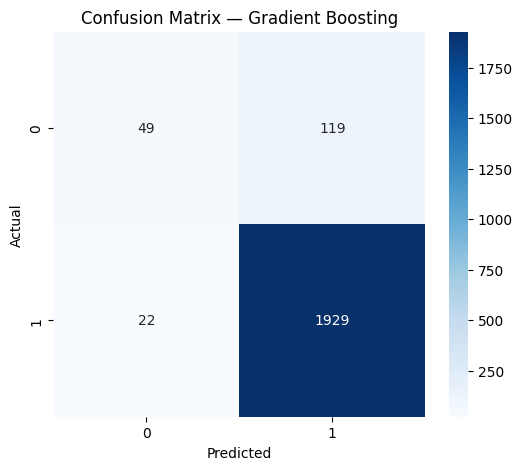

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Get predictions
best_preds = best_model.predict(X_test)
cm = confusion_matrix(y_test, best_preds)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


**Full Classification Report of Best Model**

In [ ]:
from sklearn.metrics import classification_report

print(f"Classification Report — {best_model_name}")
print(classification_report(y_test, best_preds))


Classification Report — Gradient Boosting
              precision    recall  f1-score   support

           0       0.69      0.29      0.41       168
           1       0.94      0.99      0.96      1951

    accuracy                           0.93      2119
   macro avg       0.82      0.64      0.69      2119
weighted avg       0.92      0.93      0.92      2119



**Bar Plot for Accuracy & Macro F1**

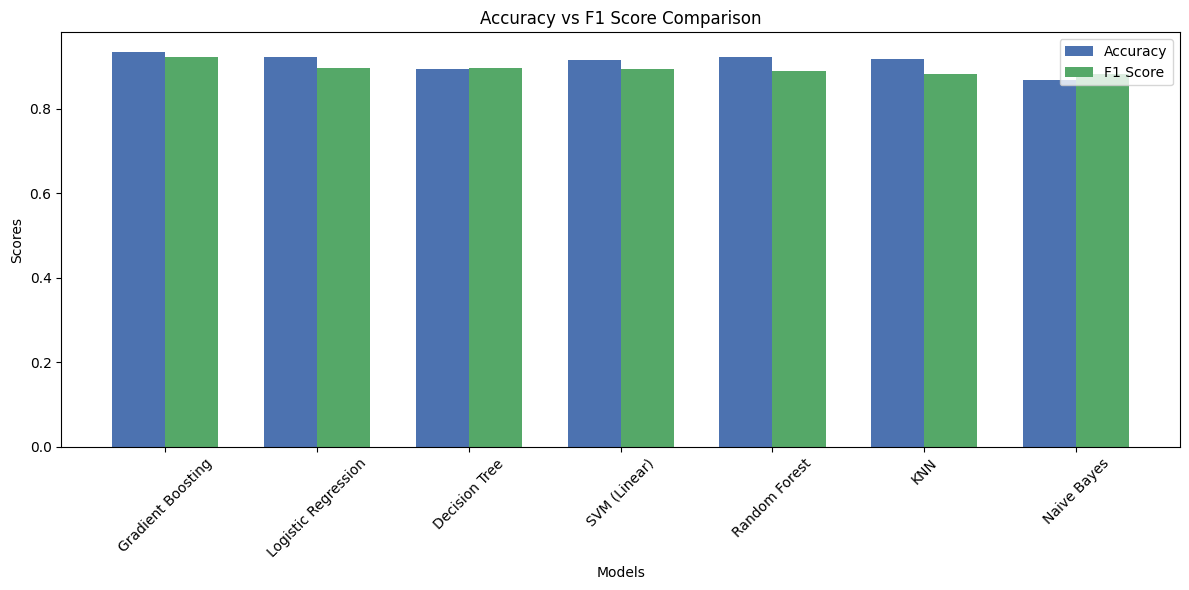

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


# Extract data
models = results_df["Model"]
accuracy = results_df["Accuracy"]
macro_f1 = results_df["F1"]

# Set bar positions
x = np.arange(len(models))
width = 0.35

# Create plot
plt.figure(figsize=(12, 6))
plt.bar(x - width/2, accuracy, width, label="Accuracy", color="#4C72B0")
plt.bar(x + width/2, macro_f1, width, label="F1 Score", color="#55A868")

# Labels and title
plt.xlabel("Models")
plt.ylabel("Scores")
plt.title("Accuracy vs F1 Score Comparison")
plt.xticks(x, models, rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

**llm vs traditional model**

In [ ]:
import pandas as pd


df_results = pd.DataFrame(results, columns=["Model", "Accuracy", "F1"])


llm_accuracy = 0.933459
llm_f1 = 0.718201

df_results = pd.concat([
    df_results,
    pd.DataFrame([["BART LLM", llm_accuracy, llm_f1]], columns=["Model", "Accuracy", "F1"])
], ignore_index=True)

df_results


,Model,Accuracy,F1
0,Logistic Regression,0.920717,0.896364
1,Decision Tree,0.894290,0.895949
2,Random Forest,0.922133,0.887857
3,Gradient Boosting,0.933459,0.920763
4,SVM (Linear),0.915526,0.893614
5,KNN,0.915998,0.882054
6,Naive Bayes,0.866918,0.881773
7,BART LLM,0.933459,0.718201


from matplotlib import pyplot as plt
df_results['Accuracy'].plot(kind='hist', bins=20, title='Accuracy')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
df_results['F1'].plot(kind='hist', bins=20, title='F1')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
import seaborn as sns
df_results.groupby('Model').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
df_results.plot(kind='scatter', x='Accuracy', y='F1', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
df_results['Accuracy'].plot(kind='line', figsize=(8, 4), title='Accuracy')
plt.gca().spines[['top', 'right']].set_visible(False)

... (14 outputs left out)

from matplotlib import pyplot as plt
_df_11['F1'].plot(kind='line', figsize=(8, 4), title='F1')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(_df_12['Model'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(_df_12, x='index', y='Model', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(_df_13['Model'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(_df_13, x='Accuracy', y='Model', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(_df_14['Model'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(_df_14, x='F1', y='Model', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

**Bar Plot: ML Models vs LLM**

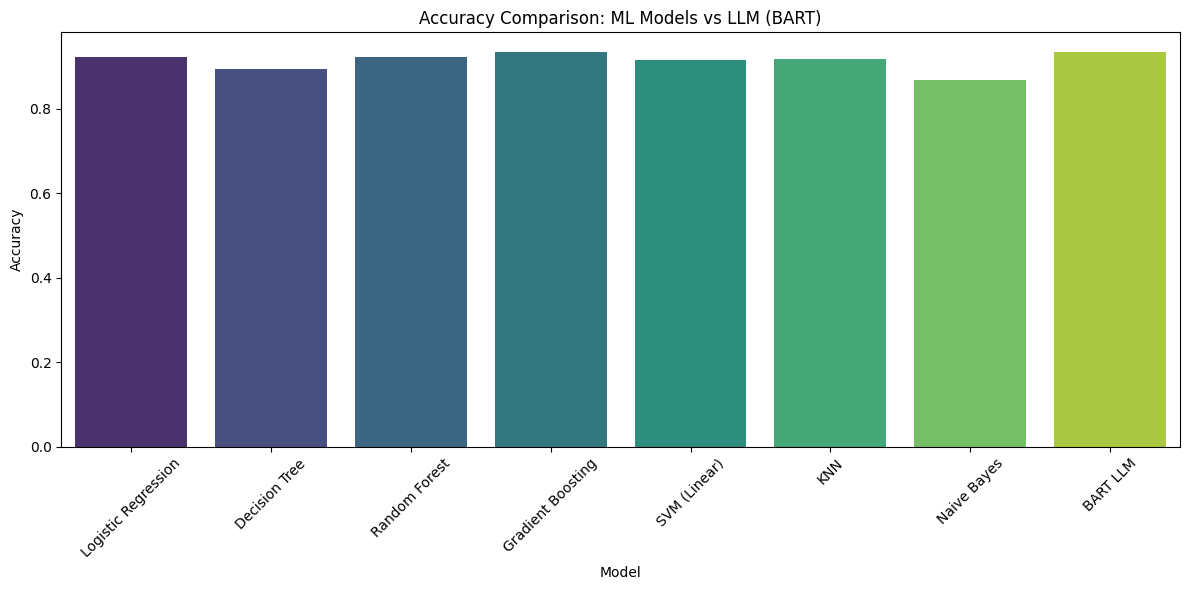

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))
sns.barplot(data=df_results, x="Model", y="Accuracy", palette="viridis")

plt.title("Accuracy Comparison: ML Models vs LLM (BART)")
plt.xticks(rotation=45)
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()



**Confusion Matrix of the BEST ML model**

In [ ]:
best_ml_name = df_results[df_results["Model"] != "BART LLM"].sort_values("F1", ascending=False).iloc[0]["Model"]
best_ml_name




'Gradient Boosting'

**Classification Report of the BEST ML model**

In [ ]:
from sklearn.metrics import classification_report

print("Classification Report for", best_ml_name)
print(classification_report(y_test, best_preds))


Classification Report for Gradient Boosting
              precision    recall  f1-score   support

           0       0.69      0.29      0.41       168
           1       0.94      0.99      0.96      1951

    accuracy                           0.93      2119
   macro avg       0.82      0.64      0.69      2119
weighted avg       0.92      0.93      0.92      2119



**Summary**

In [ ]:
best_overall = df_results.sort_values("F1", ascending=False).iloc[0]

print("SUMMARY")
print(f"Best model overall: {best_overall['Model']}")
print(f"Accuracy: {best_overall['Accuracy']:.4f}")
print(f"F1 Score: {best_overall['F1']:.4f}")

if best_overall['Model'] == "BART LLM":
    print("\nYour LLM outperformed all ML models.")
else:
    print("\nLLM doesnt outperformed.")


SUMMARY
Best model overall: Gradient Boosting
Accuracy: 0.9335
F1 Score: 0.9208

LLM doesnt outperformed.


In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_path = "life_satisfaction_BERT_model"

tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path)

model.eval()


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e

In [ ]:
def predict_sentence(sent):
    tokens = tokenizer(sent, return_tensors="pt", truncation=True)

    with torch.no_grad():
        logits = model(**tokens).logits
        pred = torch.argmax(logits, dim=1).item()

    # Convert numeric prediction → label
    if pred == 1:
        return "Satisfied"
    else:
        return "Not Satisfied"


In [ ]:
test_text = "I dont feel happy with my social life and financial stability."
prediction = predict_sentence(test_text)

print("Input:", test_text)
print("Prediction:", prediction)


Input: I dont feel happy with my social life and financial stability.
Prediction: Satisfied


In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

# Load your saved BART model
model_path = "/content/life_satisfaction_BERT_model"
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path)

def predict_sentence(sentence):
    inputs = tokenizer(sentence, return_tensors="pt", truncation=True, padding=True)
    with torch.no_grad():
        logits = model(**inputs).logits
    pred = torch.argmax(logits, dim=1).item()
    return "Satisfied 🙂" if pred == 1 else "Dissatisfied 😞"

# TEST
print(predict_sentence("I feel unhappy and stressed about my life."))
print(predict_sentence("Everything is going great lately!"))


Satisfied 🙂
Satisfied 🙂


In [ ]:

best_model = models["Gradient Boosting"]
print("Loaded Best Model:", best_model)


Loaded Best Model: GradientBoostingClassifier(random_state=42)


In [ ]:
import numpy as np
import pandas as pd


print("Column order:", list(X_train.columns))


Column order: ['Unnamed: 0', 'respnb', 'gender', 'age', 'A2', 'B1', 'B10', 'B17_a', 'C1', 'C4', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'D16', 'D17', 'E1', 'E2', 'E3', 'E5_a', 'E6', 'E11', 'E12', 'E17', 'job', 'F10', 'F11', 'F15', 'G1', 'G6', 'G7', 'G8', 'H1', 'H2', 'J1', 'J2', 'J3', 'J4', 'J8a', 'J9', 'J10', 'J11', 'J12', 'J13', 'J14', 'J15', 'J16_a', 'J17', 'J20', 'K1', 'K2', 'K3', 'K4', 'K5', 'L8_1', 'M2', 'M6', 'M7', 'M8', 'Q1', 'Q1_a', 'Q1_f', 'Q3_a', 'Q4_a', 'Q5', 'Q6', 'R10', 'R12_a', 'pervgt', 'int_result', 'method', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B9', 'B11', 'B12', 'B13', 'B14', 'education', 'G10_a', 'G11_a', 'J18', 'J18a', 'K1_a', 'N1', 'N2', 'N5', 'N8', 'N9', 'N12', 'N13', 'N16', 'Q1_b', 'Q1_e', 'Q1_g']


In [ ]:

# ✅ FIXED: Create test_df using only the selected_features.

# ✏️ REPLACE THESE VALUES with your own test values
sample_values = [
    [0] * len(selected_features) # Placeholder: Use length of selected_features
]

# Convert to DataFrame using correct columns (selected_features)
test_df = pd.DataFrame(sample_values, columns=selected_features)

# Clean column names if needed (only if clean_col_names is defined and necessary)
try:
    test_df = clean_col_names(test_df)
except NameError:
    pass # clean_col_names might not be defined if the cell above wasn't run
except Exception as e:
    print(f"Warning during column cleaning: {e}")

print("Prepared Test Input (using selected features):")
print(test_df.columns.tolist())
test_df


Prepared Test Input (using selected features):
['Unnamed: 0', 'respnb', 'age', 'A2', 'C1', 'D2', 'D4', 'D6', 'D8', 'D10', 'D14', 'D15', 'E2', 'E17', 'F15', 'G1', 'G7', 'H1', 'J14', 'M2', 'M6', 'M8', 'pervgt']


,Unnamed: 0,respnb,age,A2,C1,D2,D4,D6,D8,D10,...,E17,F15,G1,G7,H1,J14,M2,M6,M8,pervgt
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:

if 'results_df' not in locals():
    results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "F1"])
    results_df.sort_values(by="F1", ascending=False, inplace=True)
    results_df.reset_index(drop=True, inplace=True)


best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

prediction = best_model.predict(test_df)[0]

if prediction == 1:
    print("Prediction: SATISFIED")
else:
    print("Prediction: DISSATISFIED")


Prediction: DISSATISFIED


In [ ]:
probs = best_model.predict_proba(test_df)[0]
print("Class Probabilities:", probs)
print("Satisfied Probability:", probs[1])
print("Dissatisfied Probability:", probs[0])


Class Probabilities: [0.90061128 0.09938872]
Satisfied Probability: 0.09938872030204383
Dissatisfied Probability: 0.9006112796979562


In [ ]:
import numpy as np
import pandas as pd

# If you already have Gradient Boosting model trained:
# Example: model = GradientBoostingClassifier().fit(X_train, y_train)

# Assuming your trained model is stored in variable "gb_model"
# Replace this line if your variable name is different
best_model =   models[best_model_name]

print("Gradient Boosting Model Loaded.")


Gradient Boosting Model Loaded.


In [ ]:
print("=== Life Satisfaction Prediction (Gradient Boosting) ===")

age = int(input("Enter Age: "))

health = int(input("Rate your general health (0 = Very Poor, 10 = Very Good): "))

illness = int(input("Do you suffer from long‑term illness or disability? (0 = No, 1 = Yes): "))



=== Life Satisfaction Prediction (Gradient Boosting) ===
Enter Age: 40
Rate your general health (0 = Very Poor, 10 = Very Good): 5
Do you suffer from long‑term illness or disability? (0 = No, 1 = Yes): 1


In [ ]:
X3 = df[["age", "A2", "D10"]]
y3 = df["A1"].astype(int)

from sklearn.model_selection import train_test_split
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, random_state=42, stratify=y3
)



In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb3 = GradientBoostingClassifier()
gb3.fit(X3_train, y3_train)

print("3-feature Gradient Boosting model trained successfully!")


3-feature Gradient Boosting model trained successfully!


In [ ]:
print("=== Life Satisfaction Prediction (3‑Feature GB Model) ===")

age = int(input("Enter Age: "))
health = int(input("Rate your health (0–10): "))
illness = int(input("Long‑term illness? (0 = No, 1 = Yes): "))

sample = pd.DataFrame({
    "age": [age],
    "A2": [health],
    "D10": [illness]
})

pred = gb3.predict(sample)[0]
label = "Satisfied" if pred == 1 else "Dissatisfied"

print("\n----- PREDICTION -----")
print("Life Satisfaction Status:", label)
3

=== Life Satisfaction Prediction (3‑Feature GB Model) ===
Enter Age: 25
Rate your health (0–10): 1
Long‑term illness? (0 = No, 1 = Yes): 1

----- PREDICTION -----
Life Satisfaction Status: Satisfied


In [ ]:


import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
import joblib # Import joblib for saving the model


features = [
    "age",        # Age of respondent
    "A2",         # Life satisfaction question
    "B1",         # Allowances / economic perception
    "C1",         # General worry or concern levels
    "D1",         # Health or stress related
    "E1",         # Social factors
    "G1"          # Happiness / community satisfaction
]


X = df[features].copy()
y = df["A1"].astype(int)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)


gb = GradientBoostingClassifier()
gb.fit(X_train, y_train)

print("Gradient Boosting Model Successfully Trained on 7 UI Features!")

# Save the trained model
joblib.dump(gb, "gb_model_7features.pkl")
print("Saved trained model to gb_model_7features.pkl")

print("\n=== LIFE SATISFACTION PREDICTION FORM ===")

age = float(input("1️. Enter your Age: "))

print("\n2️. A2 — How satisfied are you with your life overall?")
print("   1 = Very Dissatisfied")
print("   2 = Dissatisfied")
print("   3 = Neutral")
print("   4 = Satisfied")
print("   5 = Very Satisfied")
A2 = float(input("Your Answer (1–5): "))

print("\n3️.  B1 — How is your financial condition?")
print("   1 = Very Bad")
print("   2 = Bad")
print("   3 = Average")
print("   4 = Good")
print("   5 = Very Good")
B1 = float(input("Your Answer (1–5): "))

print("\n4️.  C1 — How often do you feel stressed?")
print("   1 = Never")
print("   2 = Rarely")
print("   3 = Sometimes")
print("   4 = Often")
print("   5 = Always")
C1 = float(input("Your Answer (1–5): "))

print("\n5️.  D1 — How would you rate your health?")
print("   1 = Very Bad")
print("   2 = Bad")
print("   3 = Average")
print("   4 = Good")
print("   5 = Excellent")
D1 = float(input("Your Answer (1–5): "))

print("\n6️. E1 — How socially connected do you feel?")
print("   1 = Not connected")
print("   2 = Slightly connected")
print("   3 = Moderately connected")
print("   4 = Well connected")
print("   5 = Strongly connected")
E1 = float(input("Your Answer (1–5): "))

print("\n7️.  G1 — How happy are you in general?")
print("   1 = Very Unhappy")
print("   2 = Unhappy")
print("   3 = Neutral")
print("   4 = Happy")
print("   5 = Very Happy")
G1 = float(input("Your Answer (1–5): "))


user_df = pd.DataFrame([{
    "age": age,
    "A2": A2,
    "B1": B1,
    "C1": C1,
    "D1": D1,
    "E1": E1,
    "G1": G1
}])


pred = gb.predict(user_df)[0]
label = "Satisfied " if pred == 1 else "Dissatisfied "

print("\n===================================")
print("   Your Life Satisfaction Result")
print("===================================")
print("Prediction:", label)
print("===================================\n")


Gradient Boosting Model Successfully Trained on 7 UI Features!
Saved trained model to gb_model_7features.pkl

=== LIFE SATISFACTION PREDICTION FORM ===
1️. Enter your Age: 45

2️. A2 — How satisfied are you with your life overall?
   1 = Very Dissatisfied
   2 = Dissatisfied
   3 = Neutral
   4 = Satisfied
   5 = Very Satisfied
Your Answer (1–5): 3

3️.  B1 — How is your financial condition?
   1 = Very Bad
   2 = Bad
   3 = Average
   4 = Good
   5 = Very Good
Your Answer (1–5): 1

4️.  C1 — How often do you feel stressed?
   1 = Never
   2 = Rarely
   3 = Sometimes
   4 = Often
   5 = Always
Your Answer (1–5): 5

5️.  D1 — How would you rate your health?
   1 = Very Bad
   2 = Bad
   3 = Average
   4 = Good
   5 = Excellent
Your Answer (1–5): 1

6️. E1 — How socially connected do you feel?
   1 = Not connected
   2 = Slightly connected
   3 = Moderately connected
   4 = Well connected
   5 = Strongly connected
Your Answer (1–5): 5

7️.  G1 — How happy are you in general?
   1 = Very 

In [ ]:
!pip install streamlit


In [ ]:
import joblib
joblib.dump(best_model, "gb_model.pkl")


['gb_model.pkl']

In [ ]:
!streamlit run app.py & npx localtunnel --port 8501


⠙

⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) 
  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://104.196.136.250:8501

  Stopping...
^C


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix


In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure that X_test_sel and y_test are available from previous steps (e.g., cell J2jfTgPZsahF)
# This code assumes that the individual model training cells (for lr, rf, xgb, lgb, svm_rbf, knn)
# and cell J2jfTgPZsahF (which defines the 'models' dictionary and trained SVM Linear/Naive Bayes)
# have all been executed successfully.

# Collect all trained models into a single dictionary for plotting
all_trained_models = {}

# Add individually trained models (if their cells were executed)
if 'lr' in globals():
    all_trained_models["Logistic Regression"] = lr
if 'rf' in globals():
    all_trained_models["Random Forest"] = rf
if 'xgb' in globals():
    all_trained_models["XGBoost"] = xgb
if 'lgb' in globals():
    all_trained_models["LightGBM"] = lgb
if 'svm_rbf' in globals():
    all_trained_models["SVM (RBF)"] = svm_rbf
if 'knn' in globals():
    all_trained_models["KNN"] = knn

# Add models trained in the loop (from cell J2jfTgPZsahF), if 'models' from there is available
if 'models' in globals():
    if "SVM (Linear)" in models:
        all_trained_models["SVM (Linear)"] = models["SVM (Linear)"]
    if "Naive Bayes" in models:
        # GaussianNB model from J2jfTgPZsahF is named 'Naive Bayes'
        all_trained_models["Naive Bayes (from loop)"] = models["Naive Bayes"]

# Define clean_col_names function for LightGBM if not already defined
if 'clean_col_names' not in globals():
    def clean_col_names(df):
        cols = df.columns
        new_cols = []
        for col in cols:
            # Add '.' to the list of characters to replace
            new_col = str(col).replace(":", "_").replace(" ", "_").replace("[", "").replace("]", "").replace("<", "").replace(">", "").replace("=", "").replace(".", "_")
            new_cols.append(new_col)
        df.columns = new_cols
        return df

# Plot confusion matrix for each model
for model_name, model_instance in all_trained_models.items():
    # Handle LightGBM specific column cleaning if needed
    if model_name == "LightGBM":
        # Create a cleaned version of X_test_sel specifically for LightGBM
        X_test_sel_for_lgbm = clean_col_names(X_test_sel.copy())
        preds = model_instance.predict(X_test_sel_for_lgbm)
    else:
        preds = model_instance.predict(X_test_sel)

    cm = confusion_matrix(y_test, preds)

    plt.figure(figsize=(5,4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Dissatisfied", "Satisfied"],
        yticklabels=["Dissatisfied", "Satisfied"]
    )
    plt.title(f"Confusion Matrix — {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


NameError: name 'lr' is not defined